In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV,StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,ConfusionMatrixDisplay,RocCurveDisplay
import joblib

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

In [40]:
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [41]:
df["Survived"].value_counts()

,count
Survived,
0,549
1,342


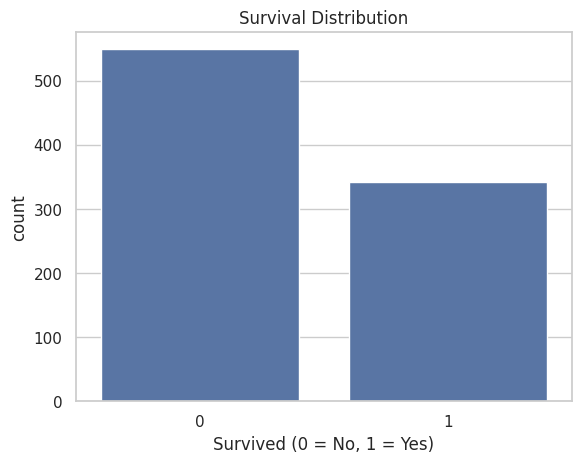

In [42]:
sns.countplot(data=df, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

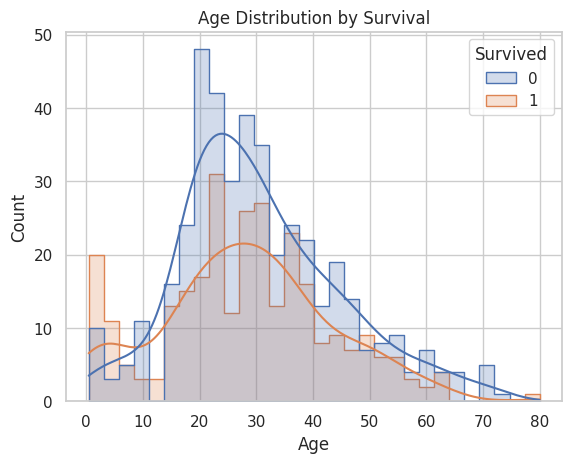

In [43]:
sns.histplot(data=df, x="Age", hue="Survived", bins=30,kde=True, element="step")
plt.title("Age Distribution by Survival")
plt.show()

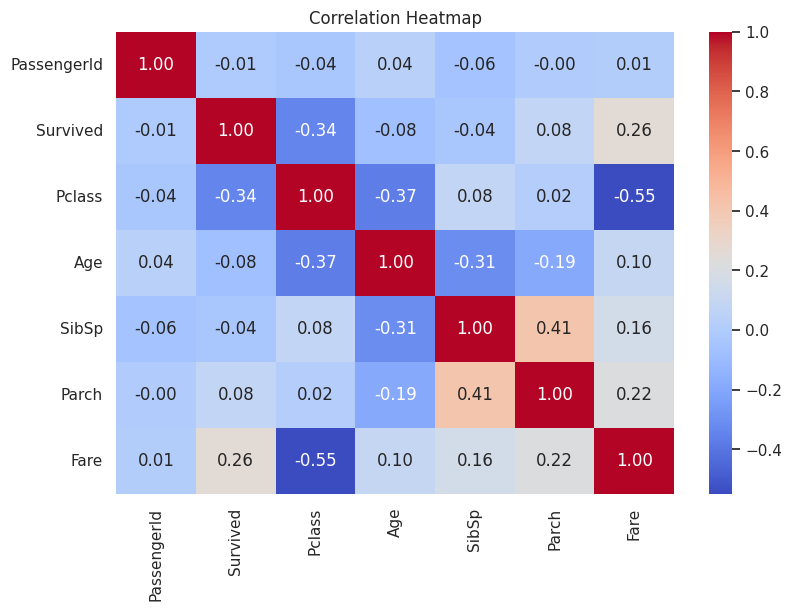

In [44]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [45]:
print(df.isnull().sum().sort_values(ascending=False))

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64


In [46]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.", expand=False)

In [47]:
df["Title"] = df["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

In [48]:
df["Title"] = df["Title"].where(
    df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]),
    "Rare"
)

In [49]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [50]:
X = df.drop(columns=["Survived"])
y = df["Survived"]
print(X.head())
print(y.head())

   Pclass     Sex   Age  SibSp  Parch     Fare Embarked  FamilySize Title
0       3    male  22.0      1      0   7.2500        S           2    Mr
1       1  female  38.0      1      0  71.2833        C           2   Mrs
2       3  female  26.0      0      0   7.9250        S           1  Miss
3       1  female  35.0      1      0  53.1000        S           2   Mrs
4       3    male  35.0      0      0   8.0500        S           1    Mr
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [52]:
numeric_features = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
categorical_features = ["Pclass", "Sex", "Embarked", "Title"]


In [53]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8379888268156425
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       110
           1       0.82      0.74      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



In [54]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42)
}

results = []

for name, clf in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", clf)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1 score": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
results_df.sort_values("ROC AUC", ascending=False).round(3)


,Model,accuracy,f1 score,ROC AUC
0,Logistic Regression,0.838,0.779,0.878
1,KNN,0.816,0.748,0.855
2,SVM,0.838,0.782,0.853
3,Random Forest,0.821,0.758,0.832


In [55]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

params = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}
grid = GridSearchCV(
    pipeline,
    params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))

Best parameters: {'model__C': 10}
Best CV ROC-AUC: 0.866


In [56]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("f1 score:", round(f1_score(y_test, y_pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 3))

accuracy: 0.838
f1 score: 0.782
ROC AUC: 0.882


In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=5, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1,
        max_depth=3, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=42
    )
}

results = []

for name, clf in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", clf)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1 score": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("ROC AUC", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,accuracy,f1 score,ROC AUC
0,Random Forest,0.821,0.754,0.852
1,Gradient Boosting,0.816,0.740,0.851
2,AdaBoost,0.799,0.723,0.847
3,Decision Tree,0.799,0.700,0.838


In [58]:
import joblib
joblib.dump(best_model, "titanic_model.joblib")

from google.colab import files
files.download("titanic_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Bundan pastdagi kodlar vibe coding

Model hammaga tushunarli bo'lishi uchun streamlit yordamida web-ilovaga integratsiya qildim

In [59]:
!pip install -q streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

cloudflared: Text file busy


In [60]:
%%writefile app.py
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Titanic Survival Predictor", page_icon="🚢", layout="centered")

@st.cache_resource
def load_model():
    return joblib.load("titanic_model.joblib")

model = load_model()

st.title("🚢 Titanic: Tirik qolish bashorati")
st.caption("Yo'lovchi ma'lumotlarini kiriting, model tirik qolish ehtimolini hisoblaydi.")

with st.form("passenger_form"):
    col1, col2 = st.columns(2)
    with col1:
        sex = st.radio("Jinsi", ["female", "male"],
                       format_func=lambda x: "Ayol" if x == "female" else "Erkak",
                       horizontal=True)
        age = st.slider("Yoshi", 0, 80, 30)
        pclass = st.selectbox("Sinf", [1, 2, 3], format_func=lambda x: f"{x}-sinf")
        title = st.selectbox("Murojaat (Title)", ["Mr", "Mrs", "Miss", "Master", "Rare"])
    with col2:
        sibsp = st.number_input("Aka-uka/er-xotin soni (SibSp)", 0, 8, 0)
        parch = st.number_input("Ota-ona/bolalar soni (Parch)", 0, 6, 0)
        fare = st.number_input("Chipta narxi (Fare)", 0.0, 520.0, 32.0, step=1.0)
        embarked = st.selectbox("Port", ["S", "C", "Q"],
                                format_func=lambda x: {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}[x])
    submitted = st.form_submit_button("Bashorat qilish", use_container_width=True)

if submitted:
    X = pd.DataFrame([{
        "Pclass": pclass, "Sex": sex, "Age": float(age),
        "SibSp": sibsp, "Parch": parch, "Fare": fare,
        "Embarked": embarked, "FamilySize": sibsp + parch + 1, "Title": title,
    }])
    prob = model.predict_proba(X)[0, 1]
    st.divider()
    st.subheader("Natija")
    st.metric("Tirik qolish ehtimoli", f"{prob:.1%}")
    st.progress(float(prob))
    if prob >= 0.5:
        st.success("✅ Tirik qolishi **ehtimoli yuqori**.")
    else:
        st.error("⚠️ Tirik qolishi **ehtimoli past**.")

st.divider()
st.caption("Model: Logistic Regression (Accuracy ≈ 0.84, ROC-AUC ≈ 0.88). Ta'lim maqsadida yaratilgan.")

Overwriting app.py


In [61]:
import subprocess, time, re

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)

tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stderr=subprocess.PIPE, text=True)
for line in tunnel.stderr:
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        print("Ilova havolasi:", m.group(0))
        break

Ilova havolasi: https://annual-cave-running-surgeon.trycloudflare.com
